# 05 - Backtesting & robustness

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
R = ROOT / 'results'

In [2]:
s = pd.read_csv(R/'performance/strategy_metrics.csv')
s[['commodity','strategy','start','weeks','ann_return','ann_vol','sharpe','sharpe_ci_lo','sharpe_ci_hi','max_drawdown','n_trades','win_rate','profit_factor','exposure','turnover_ann']].round(3)

,commodity,strategy,start,weeks,ann_return,ann_vol,sharpe,sharpe_ci_lo,sharpe_ci_hi,max_drawdown,n_trades,win_rate,profit_factor,exposure,turnover_ann
0,zc,STRAT iowa-rail,2022-01-21,246,0.003,0.090,0.031,-0.779,0.855,-0.168,33,0.515,1.062,0.598,8.125
1,zc,STRAT ridge (iowa univ.),2022-01-21,117,0.031,0.092,0.328,-0.853,1.664,-0.104,17,0.529,1.453,0.436,10.082
2,zc,STRAT best-univariate (iowa univ.),2022-01-21,176,0.048,0.079,0.593,-0.259,1.764,-0.085,21,0.619,1.725,0.517,7.839
3,zc,cash,2022-01-21,246,0.000,0.000,NaN,0.000,0.000,0.000,0,NaN,NaN,0.000,0.000
4,zc,buy_hold_1x,2022-01-21,246,-0.019,0.191,-0.098,-0.820,0.789,-0.374,27,0.519,0.921,0.797,11.203
5,zc,long_voltarget,2022-01-21,246,-0.002,0.105,-0.015,-0.775,0.878,-0.203,27,0.519,1.003,0.797,7.145
6,zc,momentum_12w,2022-01-21,246,-0.012,0.102,-0.121,-1.215,0.765,-0.286,53,0.415,0.928,0.699,13.181
7,zc,momentum_4w,2022-01-21,246,-0.012,0.100,-0.122,-1.138,0.559,-0.234,55,0.400,0.917,0.675,13.279
8,zs,STRAT iowa-rail,2021-12-31,238,0.021,0.084,0.249,-0.629,0.922,-0.111,33,0.606,1.394,0.563,9.034
9,zs,STRAT ridge (iowa univ.),2021-12-31,147,-0.043,0.078,-0.560,-1.345,0.398,-0.128,15,0.267,0.425,0.551,7.603


In [3]:
r = pd.read_csv(R/'performance/robustness.csv')
r[r.test.isin(['threshold','cost_mult','subperiod','season','price_source','execution_delay_weeks'])][['commodity','series','test','value','weeks','ann_return','sharpe','max_drawdown']].round(3)

,commodity,series,test,value,weeks,ann_return,sharpe,max_drawdown
0,zc,iowa-rail,threshold,0.0,246,0.033,0.312,-0.166
1,zc,iowa-rail,threshold,0.25,246,0.029,0.286,-0.141
2,zc,iowa-rail,threshold,0.5,246,0.003,0.031,-0.168
3,zc,iowa-rail,threshold,1.0,246,-0.030,-0.409,-0.237
4,zc,iowa-rail,threshold,1.5,246,-0.010,-0.146,-0.148
5,zc,iowa-rail,cost_mult,0,246,0.008,0.086,-0.156
6,zc,iowa-rail,cost_mult,1,246,0.003,0.031,-0.168
7,zc,iowa-rail,cost_mult,2,246,-0.002,-0.024,-0.181
8,zc,iowa-rail,cost_mult,4,246,-0.012,-0.135,-0.210
9,zc,iowa-rail,subperiod,first_half,122,0.083,0.879,-0.066


In [4]:
print(json.dumps(json.loads((R/'performance/summary.json').read_text()), indent=1))

{
 "zc": {
  "n_weeks": 847,
  "in_sample_bh_significant_h1": [
   "aar_grain_carloads__anomz"
  ],
  "in_sample_bh_significant_any": [
   [
    "aar_grain_carloads__anomz",
    1
   ],
   [
    "aar_grain_carloads__anomz",
    2
   ]
  ],
  "oos_window": [
   "2022-01-21",
   "2026-10-23"
  ],
  "permutation_p": 0.4
 },
 "zs": {
  "n_weeks": 840,
  "in_sample_bh_significant_h1": [
   "ia_railcars__anomz",
   "aar_grain_carloads__anomz"
  ],
  "in_sample_bh_significant_any": [
   [
    "ia_railcars__anomz",
    1
   ],
   [
    "aar_grain_carloads__anomz",
    1
   ],
   [
    "aar_grain_carloads__anomz",
    2
   ],
   [
    "ia_railcars__anomz",
    4
   ]
  ],
  "oos_window": [
   "2021-12-31",
   "2026-08-07"
  ],
  "permutation_p": 0.12666666666666668
 }
}


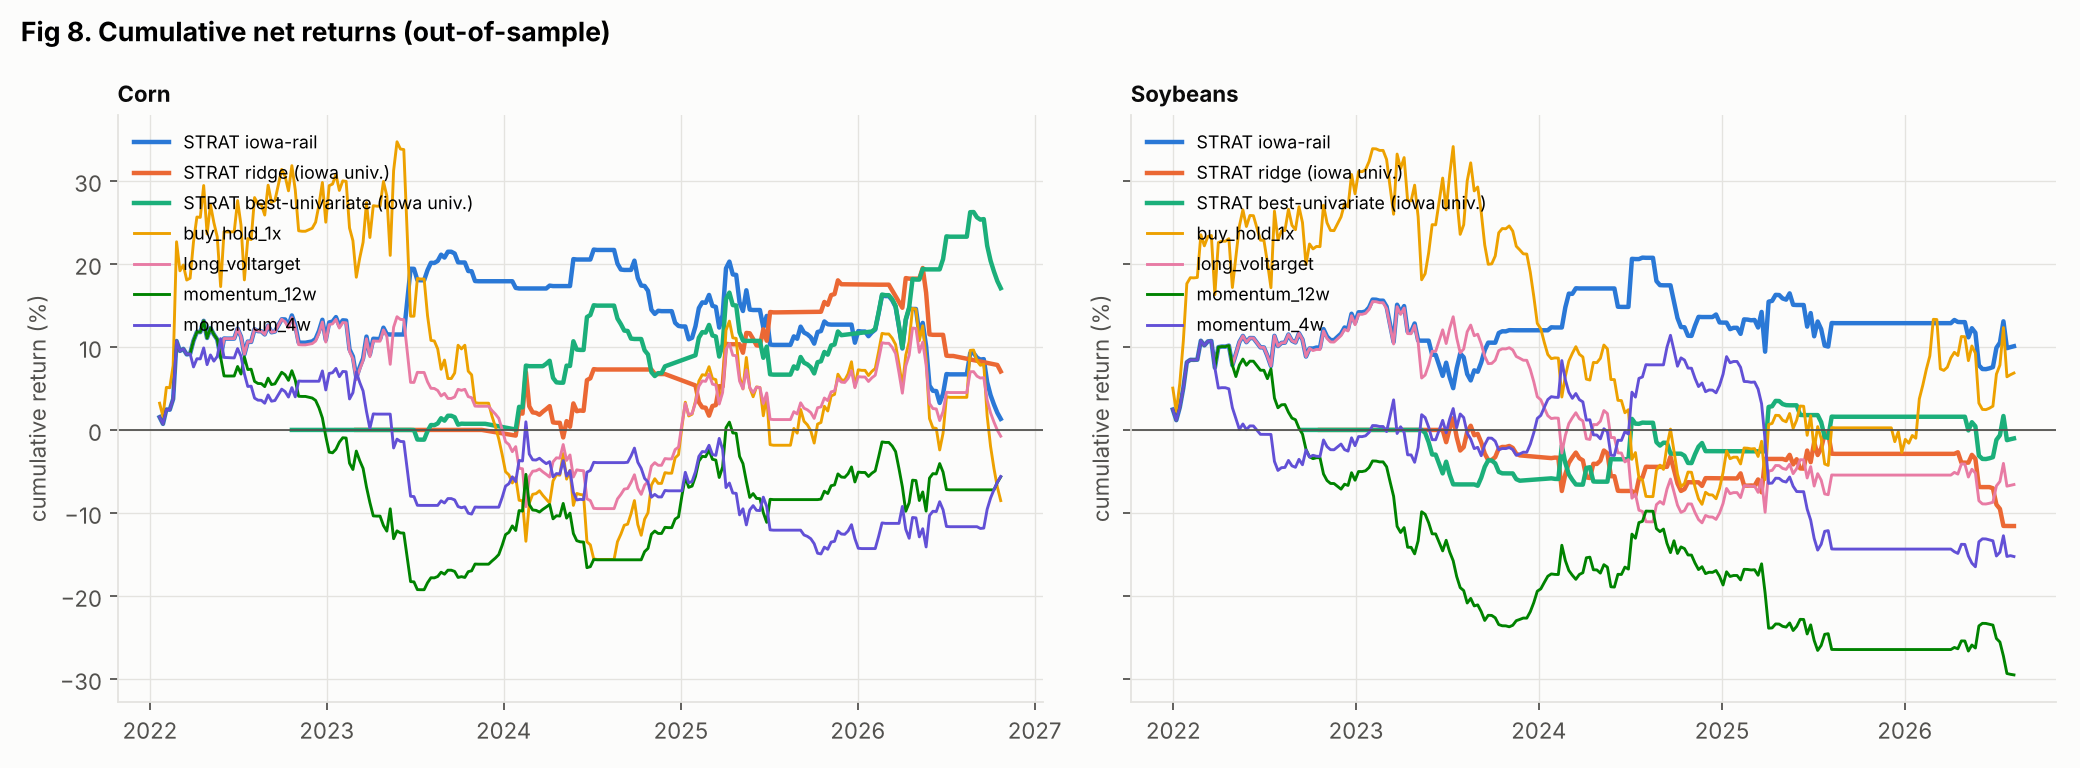

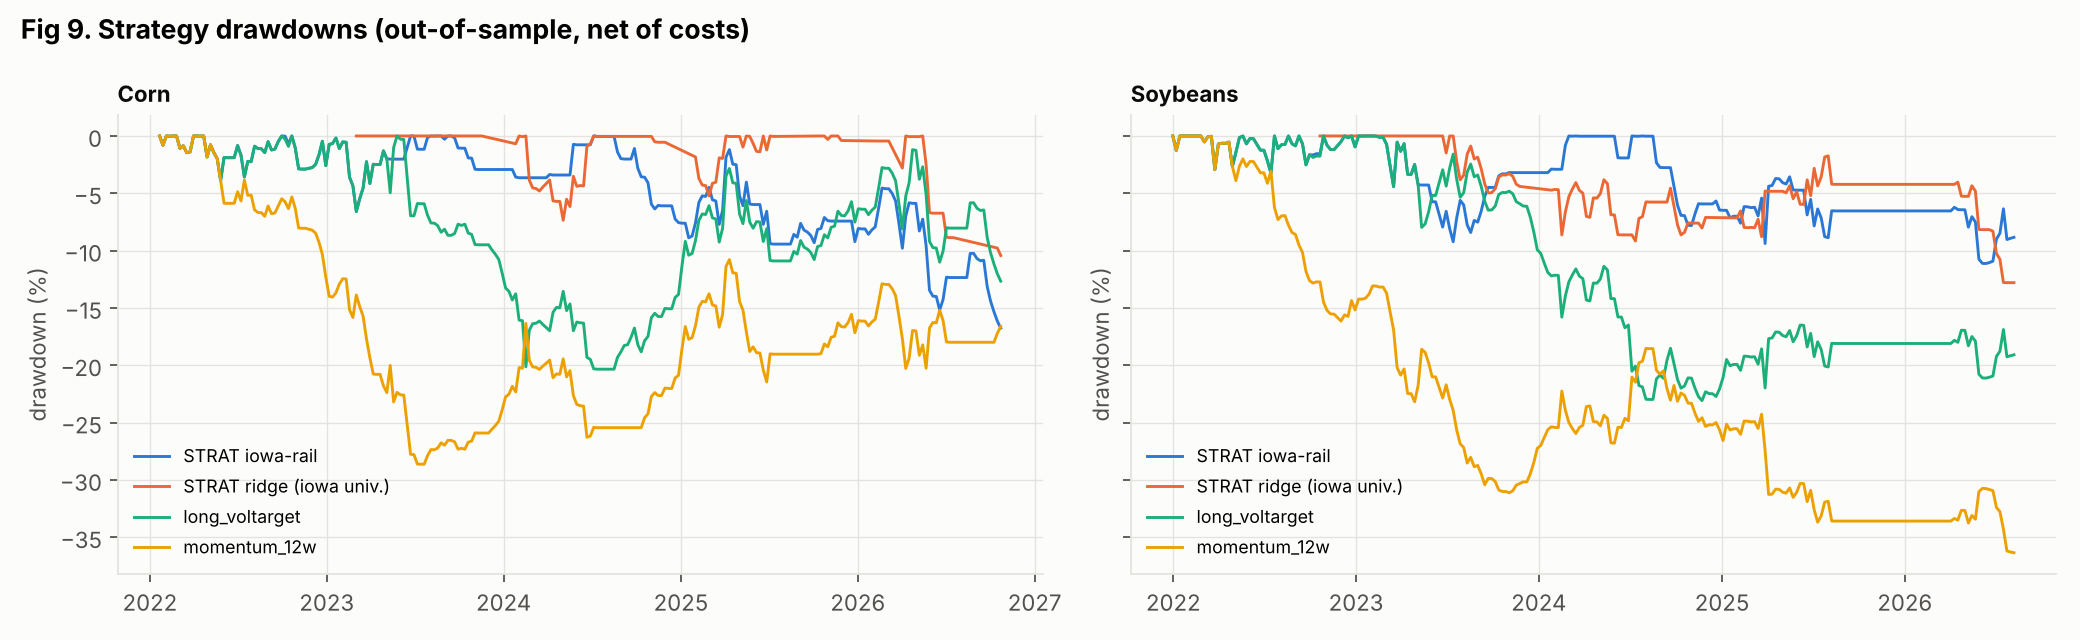

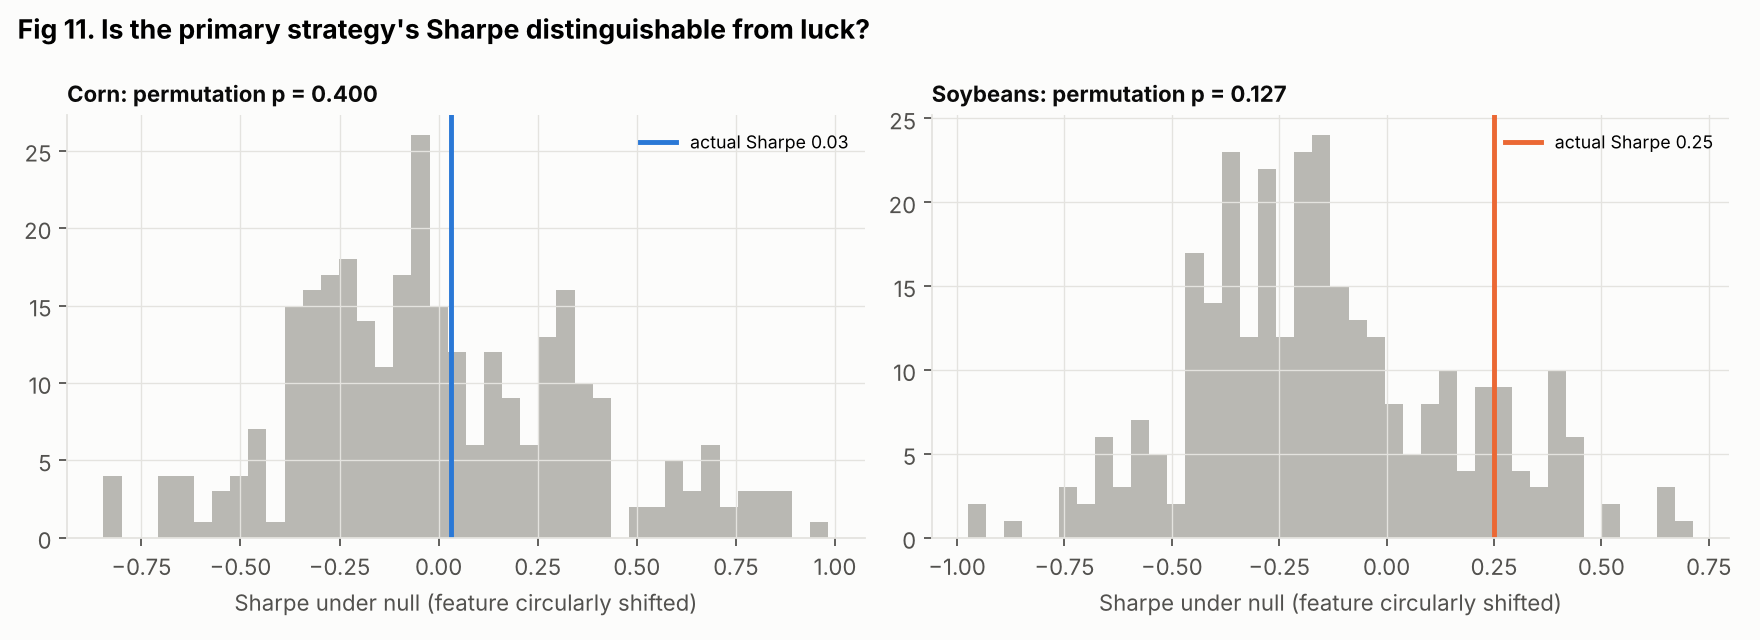

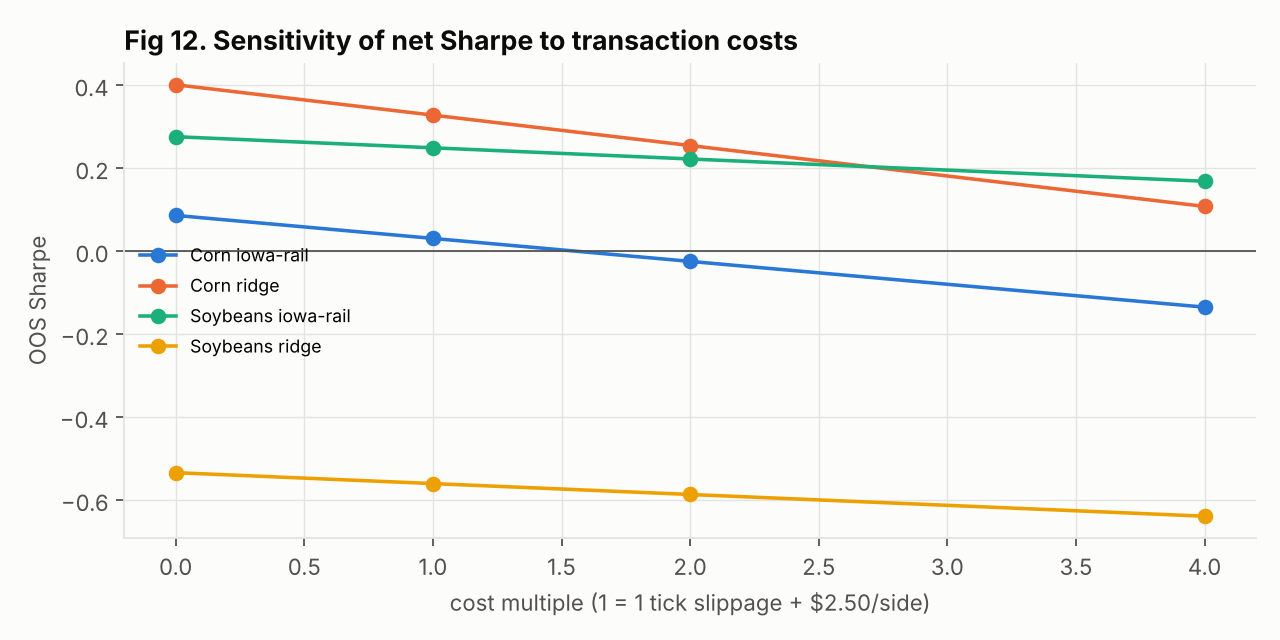

In [5]:
for f in ['08_cumulative_returns','09_drawdowns','11_permutation_test','12_cost_sensitivity']:
    display(Image(R/f'charts/{f}.png'))